In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score,confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [9]:
df = sns.load_dataset("titanic")

features = ["pclass","age","embarked","sex","fare"]
target = ["survived"]

# handling missing value
imp_median = SimpleImputer(strategy = "median")
df[["age"]] = imp_median.fit_transform(df[["age"]])

imp_most = SimpleImputer(strategy = "most_frequent") 
df[["embarked"]] = imp_most.fit_transform(df[["embarked"]])

le = LabelEncoder()
df["sex"] = le.fit_transform(df["sex"])
df["embarked"] = le.fit_transform(df["embarked"])

X = df[features]
y = df["survived"]

#train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# decision tree - no pruning
model = DecisionTreeClassifier(max_depth = 4)
model.fit(X_train,y_train)

# Evaluation

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)\

print("Training accuracy: ", accuracy_score(y_train, y_pred_train))
print("Testing accuracy: ", accuracy_score(y_test, y_pred_test))
# classic case of overfitting

Training accuracy:  0.8398876404494382
Testing accuracy:  0.7988826815642458


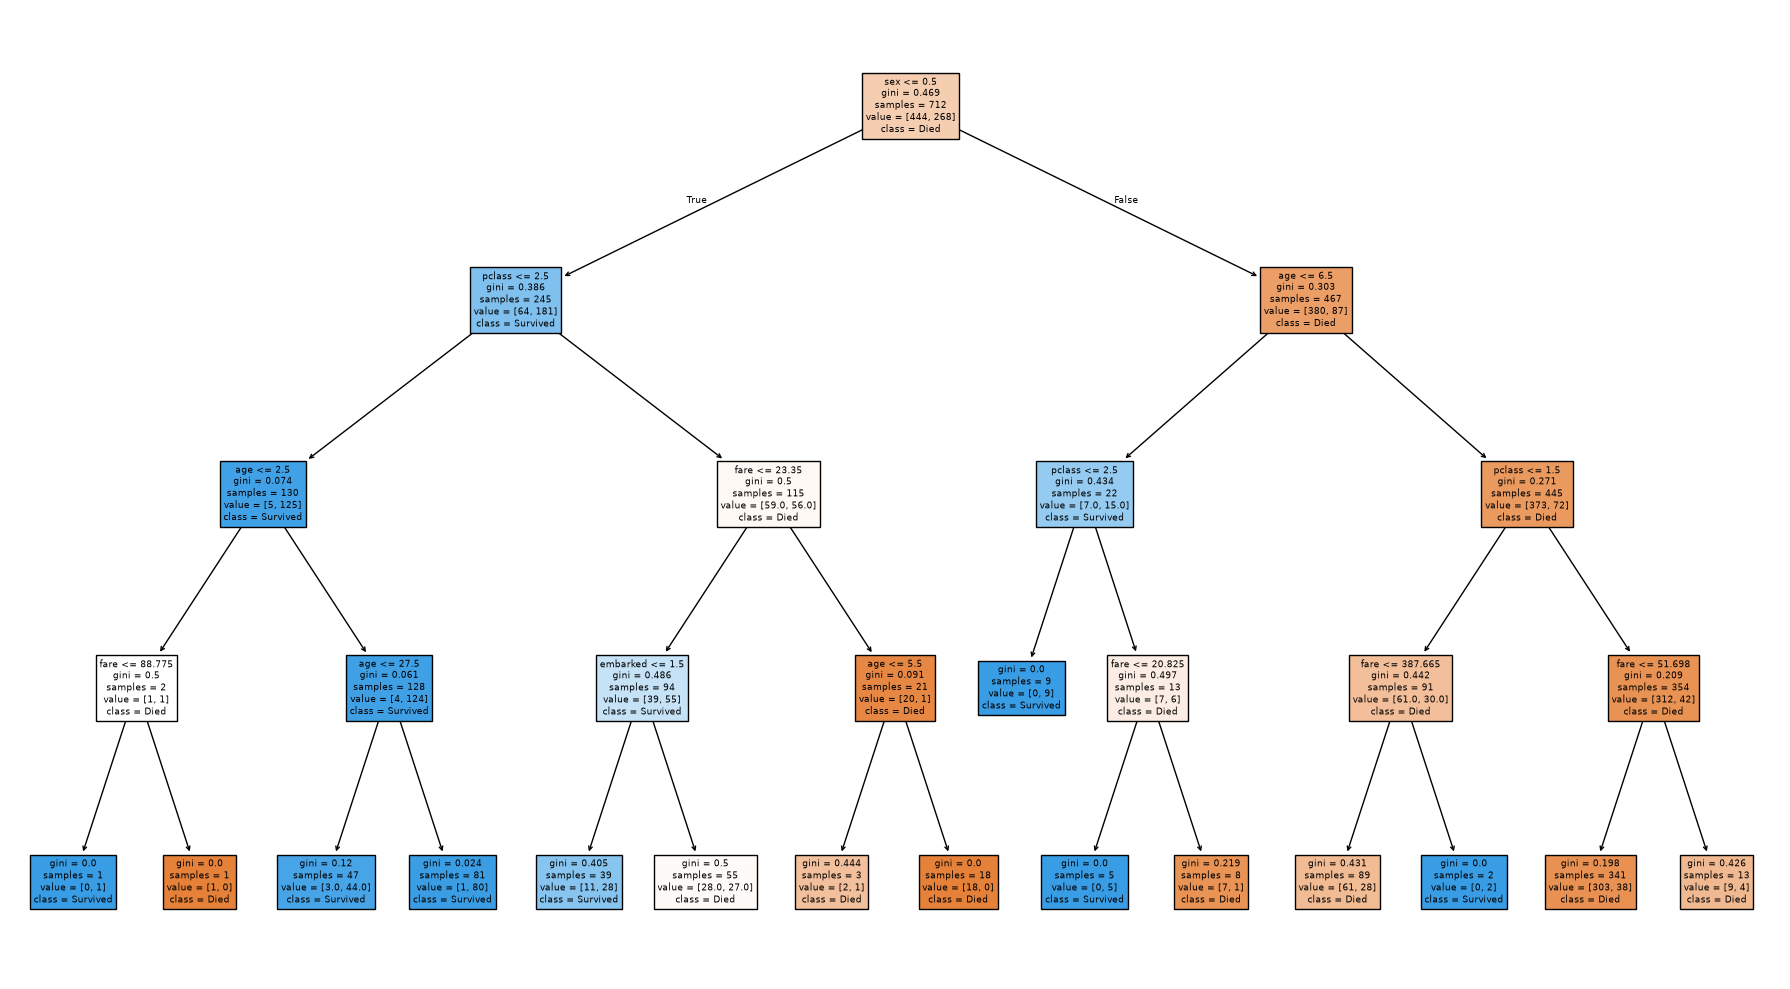

In [10]:
plt.figure(figsize = (18,10))
plot_tree(
    model,
    feature_names = X.columns,
    class_names = ["Died","Survived"],
    filled = True
)
plt.tight_layout()
plt.show()

In [11]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

In [13]:
rf = RandomForestClassifier(
    n_estimators = 501,
    oob_score = True,
    max_depth = 4
)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)

print("accuracy score :",accuracy_score(y_pred,y_test))
print("OOB score :",rf.oob_score_)


accuracy score : 0.8100558659217877
OOB score : 0.8174157303370787


In [14]:
# Bagging Classifier

from sklearn.ensemble import BaggingClassifier

base_model = DecisionTreeClassifier()

bagging = BaggingClassifier(
    base_model,
    n_estimators=201
)

bagging.fit(X_train, y_train)

y_pred = bagging.predict(X_test)

print("accuracy: ", accuracy_score(y_test, y_pred))

accuracy:  0.7988826815642458


In [15]:
# Bagging Classifier

from sklearn.linear_model import LogisticRegression

base_model = LogisticRegression(max_iter=1000)

bagging = BaggingClassifier(
    base_model,
    n_estimators=201
)

bagging.fit(X_train, y_train)

y_pred = bagging.predict(X_test)

print("accuracy: ", accuracy_score(y_test, y_pred))

accuracy:  0.7988826815642458
